# Extended scATAC classification figures (Supplementary Figures 1-3)

Figures produced:

- Supplementary Figure 1 (`scatac_macro_metrics`): per-cell-type ranked bars for AP lift, AUPRC, F1 at the best threshold, and balanced accuracy.
- Supplementary Figure 2 (`scatac_confusion_matrix`): 108 cell-type one-vs-all confusion matrix ordered by tissue category.
- Supplementary Figure 3 (`scatac_roc_umap_best_worst`): ROC curves for the four highest- and four lowest-AUC cell types, with a UMAP highlighting each.

F1, balanced accuracy, the confusion matrix, the ROC curves, and the UMAP are computed from the staged probability matrix and metadata. Reads tables from `../data/` and writes figures to `../output/`. Source: `mil/mil_nested/scatac_visualization/supp_figures.ipynb`.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from this notebook's folder (nbconvert default),
# from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)

DATA: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/data
OUT : /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm
from scipy.stats import bootstrap
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_curve, auc, precision_recall_curve,
                             balanced_accuracy_score)
from umap import UMAP
import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# Panel-family rcParams (match the source supp_figures notebook exactly).
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Liberation Sans", "Arial", "Helvetica"],
    "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 6,
    "xtick.labelsize": 5, "ytick.labelsize": 5, "legend.fontsize": 5,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "figure.dpi": 150, "savefig.dpi": 600, "pdf.fonttype": 42,
})

# OKABE_ITO palette used in the source ROC colours (vermillion distinct from blue).
ROC_PALETTE = {
    "blue": "#0072B2", "orange": "#E69F00", "green": "#009E73",
    "vermillion": "#D55E00", "sky": "#56B4E9", "yellow": "#F0E442",
    "purple": "#CC79A7",
}

CELL_TYPE_CATEGORIES = {
    'Atrial Cardiomyocyte': 'Cardiac', 'Ventricular Cardiomyocyte': 'Cardiac',
    'Cardiac Fibroblasts': 'Cardiac', 'Cardiac Pericyte 1': 'Cardiac',
    'Cardiac Pericyte 2': 'Cardiac', 'Cardiac Pericyte 3': 'Cardiac',
    'Cardiac Pericyte 4': 'Cardiac', 'Endocardial Cell': 'Cardiac',
    'Endothelial Cell (Myocardial)': 'Cardiac',
    'Pancreatic Alpha Cell 1': 'Pancreatic', 'Pancreatic Alpha Cell 2': 'Pancreatic',
    'Pancreatic Beta Cell 1': 'Pancreatic', 'Pancreatic Beta Cell 2': 'Pancreatic',
    'Pancreatic Delta,Gamma cell': 'Pancreatic', 'Pancreatic Acinar Cell': 'Pancreatic',
    'Ductal Cell (Pancreatic)': 'Pancreatic',
    'Keratinocyte 1': 'Skin', 'Keratinocyte 2': 'Skin', 'Basal Epidermal (Skin)': 'Skin',
    'Granular Epidermal (Skin)': 'Skin', 'Eccrine Epidermal (Skin)': 'Skin',
    'Melanocyte': 'Skin', 'Myoepithelial (Skin)': 'Skin',
    'Colon Epithelial Cell 1': 'Gastrointestinal', 'Colon Epithelial Cell 2': 'Gastrointestinal',
    'Colon Epithelial Cell 3': 'Gastrointestinal', 'Colonic Goblet Cell': 'Gastrointestinal',
    'Small Intestinal Enterocyte': 'Gastrointestinal', 'Small Intestinal Goblet Cell': 'Gastrointestinal',
    'Foveolar Cell': 'Gastrointestinal', 'Chief Cell': 'Gastrointestinal', 'Parietal Cell': 'Gastrointestinal',
    'Enterochromaffin Cell': 'Gastrointestinal', 'Gastric Neuroendocrine Cell': 'Gastrointestinal',
    'Paneth Cell': 'Gastrointestinal', 'Tuft Cell': 'Gastrointestinal',
    'Alveolar Type 1 (AT1) Cell': 'Respiratory', 'Alveolar Type 2 (AT2) Cell': 'Respiratory',
    'Alverolar Type 2,Immune': 'Respiratory', 'Alveolar Capillary Endothelial Cell': 'Respiratory',
    'Airway Goblet Cell': 'Respiratory', 'Club Cell': 'Respiratory', 'Cilliated Cell': 'Respiratory',
    'Esophageal Epithelial Cell': 'Esophageal', 'Smooth Muscle (Esophageal Mucosal)': 'Esophageal',
    'Smooth Muscle (Esophageal Muscularis) 1': 'Esophageal',
    'Smooth Muscle (Esophageal Muscularis) 2': 'Esophageal',
    'Smooth Muscle (Esophageal Muscularis) 3': 'Esophageal',
    'Pericyte (Esophageal Muscularis)': 'Esophageal',
    'Type I Skeletal Myocyte': 'Skeletal Muscle', 'Type II Skeletal Myocyte': 'Skeletal Muscle',
    'Satellite Cell': 'Skeletal Muscle', 'Fibroblast (Sk Muscle Associated)': 'Skeletal Muscle',
    'Mammary Epithelial': 'Mammary', 'Mammary Luminal Epithelial Cell 1': 'Mammary',
    'Mammary Luminal Epithelial Cell 2': 'Mammary', 'Basal Epithelial (Mammary)': 'Mammary',
    'Hepatocyte': 'Liver', 'Thyroid Follicular Cell': 'Thyroid',
    'Zona Fasciculata Cortical Cell': 'Adrenal', 'Zona Glomerulosa Cortical Cell': 'Adrenal',
    'Transitional Zone Cortical Cell': 'Adrenal', 'Cortical Epithelial-like': 'Adrenal',
    'Memory B Cell': 'Immune', 'Naive T cell': 'Immune', 'Natural Killer T Cell': 'Immune',
    'T Lymphocyte 1 (CD8+)': 'Immune', 'T lymphocyte 2 (CD4+)': 'Immune',
    'Plasma Cell': 'Immune', 'Mast Cell': 'Immune', 'Macrophage (General)': 'Immune',
    'Macrophage (General,Alveolar)': 'Immune',
    'Smooth Muscle (General)': 'Smooth Muscle', 'Smooth Muscle (General Gastrointestinal)': 'Smooth Muscle',
    'Smooth Muscle (Colon) 1': 'Smooth Muscle', 'Smooth Muscle (Colon) 2': 'Smooth Muscle',
    'Smooth Muscle (GE Junction)': 'Smooth Muscle', 'Smooth Muscle (Uterine)': 'Smooth Muscle',
    'Smooth Muscle (Vaginal)': 'Smooth Muscle', 'Vascular Smooth Muscle 1': 'Smooth Muscle',
    'Vascular Smooth Muscle 2': 'Smooth Muscle',
    'Endothelial Cell (General) 1': 'Endothelial', 'Endothelial Cell (General) 2': 'Endothelial',
    'Endothelial Cell (General) 3': 'Endothelial', 'Lymphatic Endothelial Cell': 'Endothelial',
    'Blood Brain Barrier Endothelial Cell': 'Endothelial', 'Endothelial (Exocrine Tissues)': 'Endothelial',
    'Fibroblast (General)': 'Stromal', 'Fibroblast (Epithelial)': 'Stromal',
    'Fibroblast (Gastrointestinal)': 'Stromal', 'Fibroblast (Liver Adrenal)': 'Stromal',
    'Fibroblast (Peripheral Nerve)': 'Stromal', 'Pericyte (General) 1': 'Stromal',
    'Pericyte (General) 2': 'Stromal', 'Pericyte (General) 3': 'Stromal',
    'Pericyte (General) 4': 'Stromal', 'Mesothelial Cell': 'Stromal',
    'CNS,Enteric Neuron': 'Neural', 'Schwann Cell (General)': 'Neural',
    'Peripheral Nerve Stromal': 'Neural',
    'Adipocyte': 'Adipose', 'Luteal Cell (Ovarian)': 'Reproductive',
}
CATEGORY_COLORS = {
    'Cardiac': '#009E73', 'Pancreatic': '#E69F00', 'Skin': '#CC79A7',
    'Gastrointestinal': '#D55E00', 'Respiratory': '#56B4E9', 'Immune': '#0072B2',
    'Liver': '#000000', 'Adipose': '#F0E442', 'Esophageal': '#882255',
    'Skeletal Muscle': '#AA4499', 'Mammary': '#DDCC77', 'Thyroid': '#88CCEE',
    'Adrenal': '#44AA99', 'Smooth Muscle': '#999933', 'Endothelial': '#332288',
    'Stromal': '#117733', 'Neural': '#661100', 'Reproductive': '#6699CC',
}
print("imports + dicts ready")

imports + dicts ready


In [3]:
# Load staged tables.
metrics_df = pd.read_csv(DATA / "scatac_task_metrics.csv")
metrics_df["category"] = metrics_df["case_label"].map(CELL_TYPE_CATEGORIES)
task_to_label = dict(zip(metrics_df["task"], metrics_df["case_label"]))

prob_matrix = pd.read_csv(DATA / "scatac_probability_matrix.csv", index_col=0)
metadata = pd.read_csv(DATA / "scatac_metadata_minimal.csv")
sample_to_celltype = dict(zip(metadata["sample_id"], metadata["group"]))
prob_matrix["true_celltype"] = prob_matrix.index.map(sample_to_celltype)
prob_matrix["category"] = prob_matrix["true_celltype"].map(CELL_TYPE_CATEGORIES).fillna("Other")

exclude_cols = {"true_celltype", "category", "umap1", "umap2", "entropy"}
task_cols = [c for c in prob_matrix.columns if c not in exclude_cols]

# Reconstruct the long-format per-task predictions (y_true, y_prob) that the source
# notebook read from all_predictions.csv. For each one-vs-all task X_vs_all the case
# label is task_to_label[X]; y_true marks cells whose true cell type == that label,
# y_prob is the staged per-task probability. This reproduces metric AUC exactly.
true_ct = prob_matrix["true_celltype"].values
pred_records = []
for task in task_cols:
    label = task_to_label.get(task)
    y_true = (true_ct == label).astype(int)
    y_prob = prob_matrix[task].values
    pred_records.append((task, label, y_true, y_prob))

print(f"Tasks: {len(metrics_df)}, Samples: {len(prob_matrix):,}, "
      f"True cell types: {prob_matrix['true_celltype'].nunique()}")

Tasks: 102, Samples: 10,131, True cell types: 108


In [4]:
def compute_max_f1(y_true, y_prob):
    """Max F1 over all thresholds from the precision-recall curve."""
    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    denom = precision + recall
    f1_vals = np.where(denom > 0, 2 * precision * recall / denom, 0.0)
    return np.max(f1_vals)


def compute_balanced_accuracy_youden(y_true, y_prob):
    """Balanced accuracy at Youden's J optimal threshold."""
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)
    best_thresh = thresholds[best_idx]
    y_pred = (y_prob >= best_thresh).astype(int)
    return balanced_accuracy_score(y_true, y_pred)


ba_records = []
for task, label, y_true, y_prob in pred_records:
    ba = compute_balanced_accuracy_youden(y_true, y_prob)
    f1 = compute_max_f1(y_true, y_prob)
    cat = CELL_TYPE_CATEGORIES.get(label, "Other")
    ba_records.append({"task": task, "case_label": label, "category": cat,
                       "balanced_accuracy": ba, "max_f1": f1})
ba_df = pd.DataFrame(ba_records)
print(f"Computed balanced accuracy (Youden) & max F1 for {len(ba_df)} tasks")
print(f"Balanced accuracy: mean={ba_df['balanced_accuracy'].mean():.3f}, "
      f"median={ba_df['balanced_accuracy'].median():.3f}")
print(f"Max F1 score:      mean={ba_df['max_f1'].mean():.3f}, "
      f"median={ba_df['max_f1'].median():.3f}")

Computed balanced accuracy (Youden) & max F1 for 102 tasks
Balanced accuracy: mean=0.877, median=0.877
Max F1 score:      mean=0.361, median=0.347


## Supplementary Figure 1: `scatac_macro_metrics`

Four stacked ranked bar panels. Each cell type is one bar, ranked high to low within the
panel. Green = top 4, vermillion/orange = bottom 4 (with representative labels), blue =
the rest. Dashed grey line = across-cell-type mean; shaded grey band = bootstrap 95% CI
of that mean (the IQR-like spread). Solid lines: (b) median baseline prevalence, (d)
chance level 0.5.

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_macro_metrics.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_macro_metrics.png


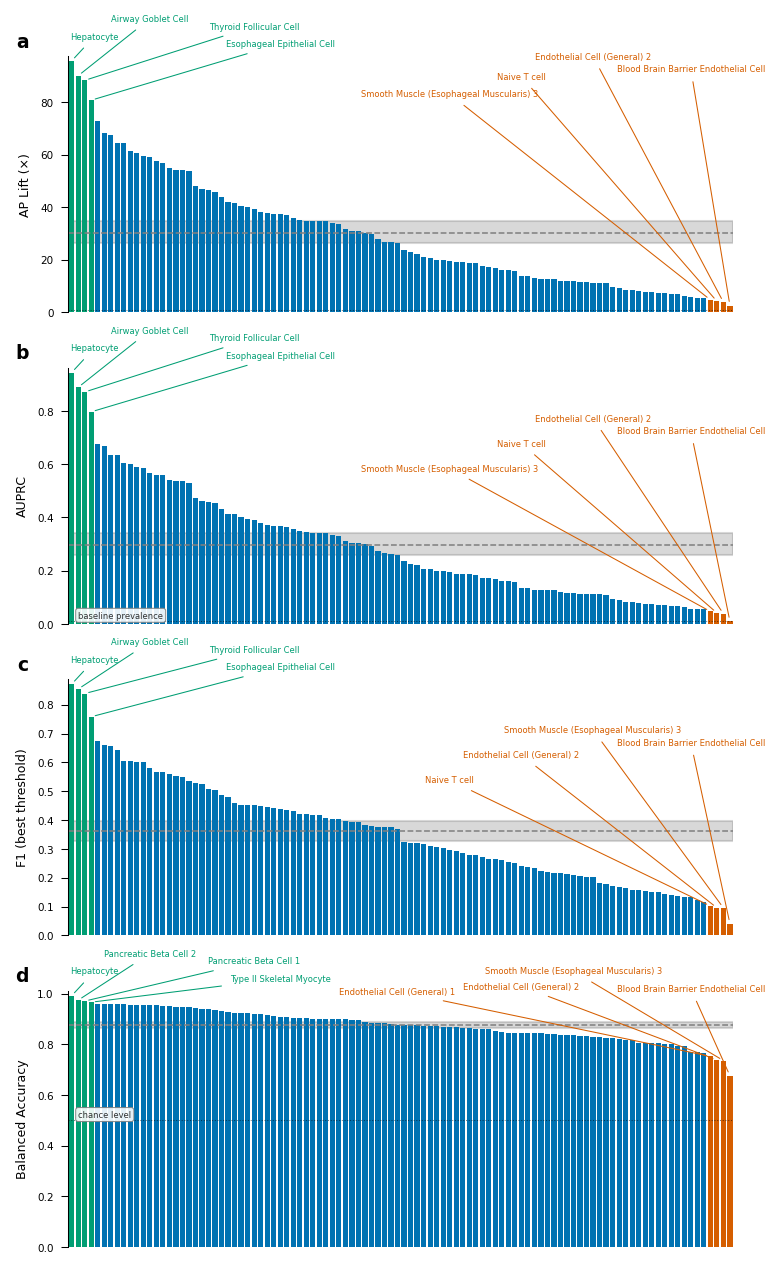

In [5]:
def ranked_panel(ax, df_plot, value_col, ylabel, top_xy, bot_xy,
                 baseline=None, baseline_label=None):
    """One ranked bar panel matching the source supp-figure style."""
    n = len(df_plot)
    top4 = df_plot.head(4)["case_label"].tolist()
    bot4 = df_plot.tail(4)["case_label"].tolist()
    colors = ["#009E73" if ct in top4 else "#D55E00" if ct in bot4 else "#0072B2"
              for ct in df_plot["case_label"]]
    ax.bar(np.arange(n), df_plot[value_col], color=colors, width=0.8, edgecolor="none")

    vals = df_plot[value_col].values
    rng = np.random.default_rng(42)
    res = bootstrap((vals,), np.mean, n_resamples=10000, confidence_level=0.95,
                    method="BCa", random_state=rng)
    grand_mean = vals.mean()
    ci_low, ci_high = res.confidence_interval
    ax.axhspan(ci_low, ci_high, color="gray", alpha=0.3, zorder=0)
    ax.axhline(grand_mean, color="gray", lw=0.75, ls="--", alpha=1.0)

    if baseline is not None:
        ax.axhline(baseline, color="black", lw=0.5, ls=":", alpha=0.5)
        if baseline_label:
            ax.text(1, baseline + (0.005 if baseline < 1 else baseline * 0.02),
                    baseline_label, fontsize=4, ha="left", va="bottom", alpha=0.8,
                    bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                              edgecolor="gray", linewidth=0.5, alpha=0.9))

    y_max = df_plot[value_col].max()
    top_idx = df_plot.head(4).index.tolist()
    for i, (xt, yf) in zip(top_idx, top_xy):
        row = df_plot.iloc[i]
        ax.annotate(row["case_label"], xy=(i, row[value_col]),
                    xytext=(xt, y_max * yf), fontsize=4, va="bottom", ha="center",
                    color="#009E73", clip_on=False, annotation_clip=False,
                    arrowprops=dict(arrowstyle="-", color="#009E73", lw=0.5))
    bot_idx = df_plot.tail(4).index.tolist()
    for i, (xt, yf) in zip(bot_idx, bot_xy):
        row = df_plot.iloc[i]
        ax.annotate(row["case_label"], xy=(i, row[value_col]),
                    xytext=(xt, y_max * yf), fontsize=4, va="bottom", ha="center",
                    color="#D55E00", clip_on=False, annotation_clip=False,
                    arrowprops=dict(arrowstyle="-", color="#D55E00", lw=0.5))

    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(0, y_max * 1.02)
    ax.set_xticks([])
    ax.set_ylabel(ylabel, fontsize=6)
    for s in ("top", "right", "bottom"):
        ax.spines[s].set_visible(False)
    return grand_mean, ci_low, ci_high


fig, axes = plt.subplots(4, 1, figsize=(5.2, 8.4))
n = len(metrics_df)
median_baseline = metrics_df["baseline_rate"].median()

# (a) AP lift
ranked_panel(axes[0],
             metrics_df.sort_values("ap_lift_mult", ascending=False).reset_index(drop=True),
             "ap_lift_mult", "AP Lift (\u00d7)",
             top_xy=[(3.5, 1.08), (12, 1.15), (28, 1.12), (32, 1.05)],
             bot_xy=[(n-44, 0.85), (n-33, 0.92), (n-22, 1.0), (n-7, 0.95)],
             baseline=1.0)
# (b) AUPRC
ranked_panel(axes[1],
             metrics_df.sort_values("ap", ascending=False).reset_index(drop=True),
             "ap", "AUPRC",
             top_xy=[(3.5, 1.08), (12, 1.15), (28, 1.12), (32, 1.05)],
             bot_xy=[(n-44, 0.6), (n-33, 0.7), (n-22, 0.8), (n-7, 0.75)],
             baseline=median_baseline, baseline_label="baseline prevalence")
# (c) F1 best threshold
ranked_panel(axes[2],
             ba_df.sort_values("max_f1", ascending=False).reset_index(drop=True),
             "max_f1", "F1 (best threshold)",
             top_xy=[(3.5, 1.08), (12, 1.15), (28, 1.12), (32, 1.05)],
             bot_xy=[(n-44, 0.6), (n-33, 0.7), (n-22, 0.8), (n-7, 0.75)])
# (d) Balanced accuracy
ranked_panel(axes[3],
             ba_df.sort_values("balanced_accuracy", ascending=False).reset_index(drop=True),
             "balanced_accuracy", "Balanced Accuracy",
             top_xy=[(3.5, 1.08), (12, 1.15), (28, 1.12), (32, 1.05)],
             bot_xy=[(n-52, 1.0), (n-33, 1.02), (n-25, 1.08), (n-7, 1.01)],
             baseline=0.5, baseline_label="chance level")

for ax, lab in zip(axes, "abcd"):
    ax.text(-0.06, 1.02, lab, transform=ax.transAxes, fontsize=9,
            fontweight="bold", va="bottom", ha="right")

plt.tight_layout()
savefig(fig, OUT, "scatac_macro_metrics")
plt.show()

## Supplementary Figure 2: `scatac_confusion_matrix`

108-cell-type one-vs-all confusion matrix. Each entry is the mean per-task probability
assigned to cells of a given true cell type, i.e. `prob_matrix.groupby(true_celltype)[task_cols].mean()`,
with columns renamed from task to case label. Rows and columns are ordered by tissue
category; the warm colour bars on the top and left annotate the category. Intensity is a
quantile-binned white-to-warm map of classification frequency (matching the source).

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_confusion_matrix.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_confusion_matrix.png


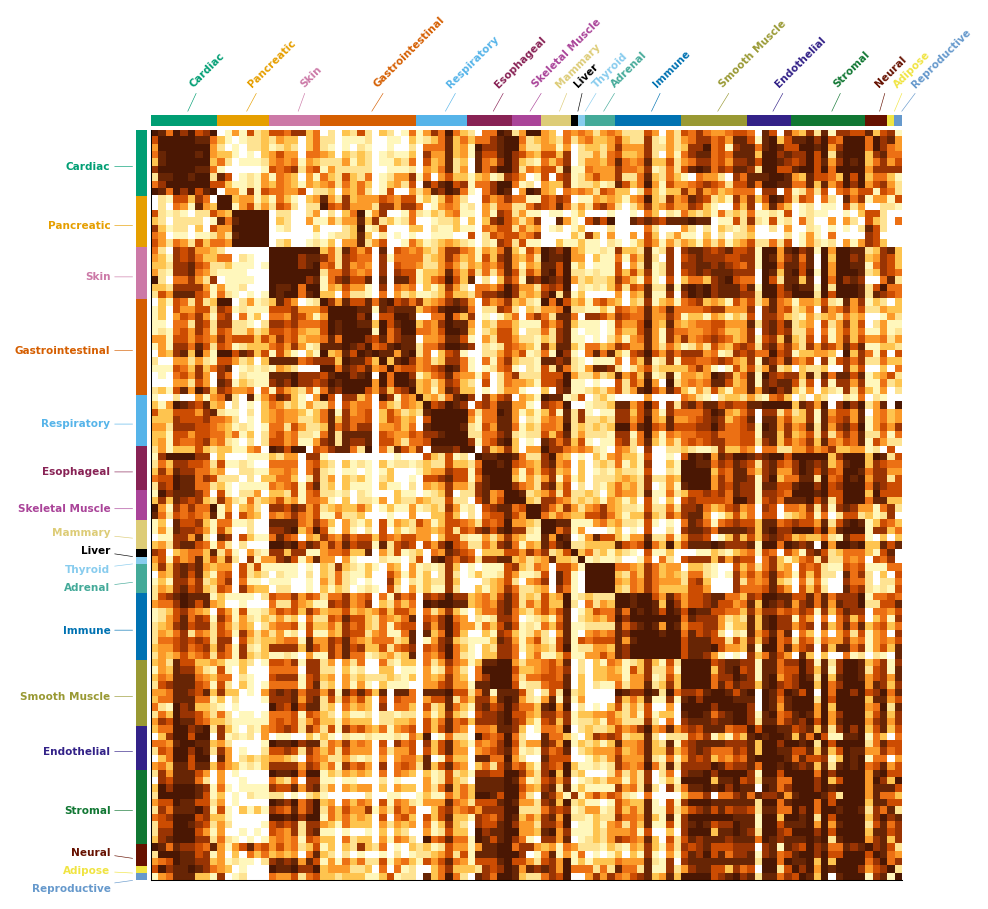

Diagonal mean: 0.664
Off-diagonal mean: 0.1006


In [6]:
col_rename = {c: task_to_label.get(c, c) for c in task_cols}
conf = prob_matrix.groupby("true_celltype")[task_cols].mean()
conf = conf.rename(columns=col_rename)

ct_categories = pd.Series({ct: CELL_TYPE_CATEGORIES.get(ct, "Other") for ct in conf.index})
cat_order_conf = ['Cardiac', 'Pancreatic', 'Skin', 'Gastrointestinal', 'Respiratory',
                  'Esophageal', 'Skeletal Muscle', 'Mammary', 'Liver', 'Thyroid',
                  'Adrenal', 'Immune', 'Smooth Muscle', 'Endothelial', 'Stromal',
                  'Neural', 'Adipose', 'Reproductive']

sorted_cts, cat_boundaries = [], []
for cat in cat_order_conf:
    cts_in_cat = sorted([ct for ct in conf.index if ct_categories.get(ct) == cat])
    if cts_in_cat:
        cat_boundaries.append((len(sorted_cts), len(sorted_cts) + len(cts_in_cat), cat))
        sorted_cts.extend(cts_in_cat)

# Only keep columns that exist (tasks); rows are all 108 true cell types.
conf = conf.loc[sorted_cts, [c for c in sorted_cts if c in conf.columns]]
n = len(conf)

cmap_colors = ['#FFFFFF', '#FFF7BC', '#FEE391', '#FEC44F', '#FB9A29',
               '#EC7014', '#CC4C02', '#993404', '#662506', '#4A1703']
bounds = np.quantile(conf.values.ravel(), np.linspace(0, 1, len(cmap_colors) + 1))
bounds = np.unique(bounds)
cmap = LinearSegmentedColormap.from_list("prob_heat", cmap_colors, N=256)
norm = BoundaryNorm(bounds, cmap.N)


def space_labels(cat_boundaries, min_gap=2.5):
    pos = [(start + end) / 2 for start, end, _ in cat_boundaries]
    for _ in range(100):
        moved = False
        for i in range(len(pos) - 1):
            gap = pos[i + 1] - pos[i]
            if gap < min_gap:
                shift = (min_gap - gap) / 2
                pos[i] -= shift
                pos[i + 1] += shift
                moved = True
        if not moved:
            break
    return pos

label_positions = space_labels(cat_boundaries, min_gap=2.5)

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.imshow(conf.values, cmap=cmap, norm=norm, aspect="equal", interpolation="none")

for start, end, cat in cat_boundaries:
    color = CATEGORY_COLORS.get(cat, "#999999")
    ax.add_patch(Rectangle((-2.5, start - 0.5), 1.5, end - start,
                           facecolor=color, edgecolor="none", clip_on=False))
    ax.add_patch(Rectangle((start - 0.5, -2.5), end - start, 1.5,
                           facecolor=color, edgecolor="none", clip_on=False))

for (start, end, cat), lbl_y in zip(cat_boundaries, label_positions):
    color = CATEGORY_COLORS.get(cat, "#999999")
    mid_y = (start + end) / 2
    ax.annotate(cat, xy=(-3, mid_y), xytext=(-6, lbl_y), ha="right", va="center",
                fontsize=5, color=color, fontweight="bold", clip_on=False,
                annotation_clip=False,
                arrowprops=dict(arrowstyle="-", color=color, lw=0.3, shrinkA=0, shrinkB=0))
for (start, end, cat), lbl_x in zip(cat_boundaries, label_positions):
    color = CATEGORY_COLORS.get(cat, "#999999")
    mid_x = (start + end) / 2
    ax.annotate(cat, xy=(mid_x, -3), xytext=(lbl_x, -6), ha="left", va="bottom",
                fontsize=5, rotation=45, color=color, fontweight="bold", clip_on=False,
                annotation_clip=False,
                arrowprops=dict(arrowstyle="-", color=color, lw=0.3, shrinkA=0, shrinkB=0))

ax.set_xticks([]); ax.set_yticks([])
savefig(fig, OUT, "scatac_confusion_matrix")
plt.show()
print(f"Diagonal mean: {np.diag(conf.values).mean():.3f}")
print(f"Off-diagonal mean: {conf.values[~np.eye(len(conf), dtype=bool)].mean():.4f}")

## Supplementary Figure 3: `scatac_roc_umap_best_worst`

(a) ROC curves for the 4 highest-AUC and the 4 lowest-AUC cell types (one panel each),
computed from the reconstructed per-task `y_true`/`y_prob`.
(b) UMAP of the per-cell one-vs-all probability profiles (logit transform → StandardScaler
→ UMAP `n_neighbors=15, min_dist=0.5, metric=cosine, random_state=42`, identical to the
main notebook). Each of the 8 best/worst cell types is highlighted in orange vs grey, with
its AUC labelled above.

In [7]:
# Recompute the UMAP exactly like the main notebook's fig03c cell.
X = prob_matrix[task_cols].to_numpy(dtype=float)
eps = 1e-5
Xl = np.clip(X, eps, 1 - eps)
Xl = np.log(Xl / (1 - Xl))
Xl = StandardScaler().fit_transform(Xl)
emb = UMAP(n_neighbors=15, min_dist=0.5, spread=1.0, metric="cosine",
           random_state=42).fit_transform(Xl)
prob_matrix["umap1"], prob_matrix["umap2"] = emb[:, 0], emb[:, 1]
print("UMAP computed:", emb.shape)

UMAP computed: (10131, 2)


saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_roc_umap_best_worst.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_roc_umap_best_worst.png


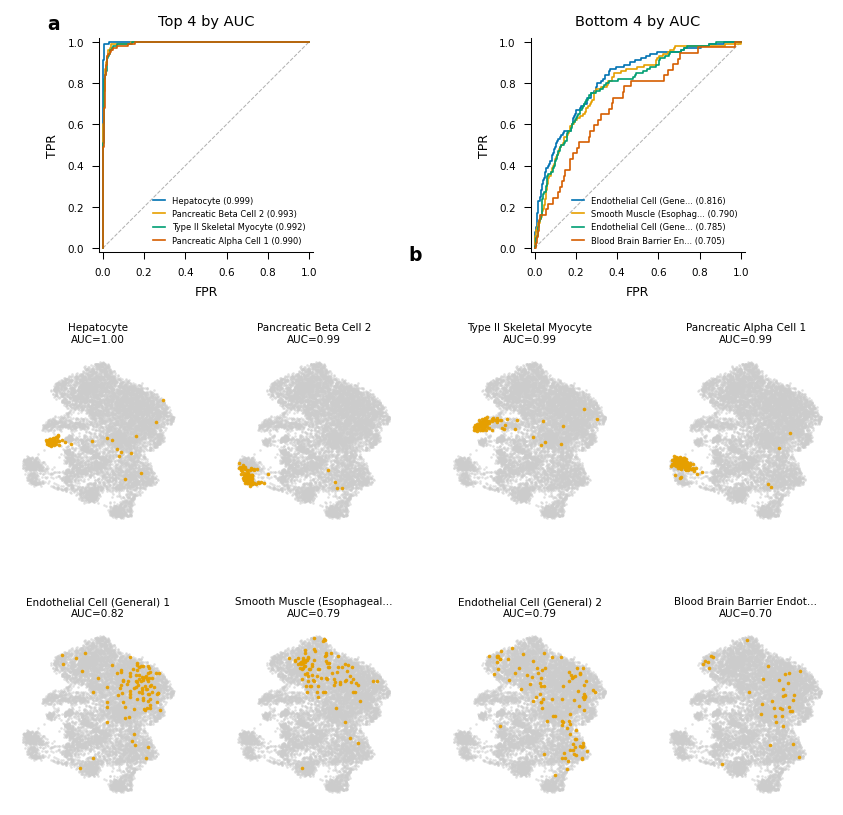

In [8]:
df_sorted = metrics_df.sort_values("auc", ascending=False).reset_index(drop=True)
top4 = df_sorted.head(4)["case_label"].tolist()
bottom4 = df_sorted.tail(4)["case_label"].tolist()
label_to_auc = dict(zip(metrics_df["case_label"], metrics_df["auc"]))
label_to_task = {v: k for k, v in task_to_label.items()}

# Reconstructed per-task arrays keyed by case label.
pred_by_label = {label: (yt, yp) for (task, label, yt, yp) in pred_records}

roc_colors = [ROC_PALETTE["blue"], ROC_PALETTE["orange"],
              ROC_PALETTE["green"], ROC_PALETTE["vermillion"]]

fig = plt.figure(figsize=(7.0, 6.6))
gs = fig.add_gridspec(3, 4, height_ratios=[1.25, 1, 1], hspace=0.55, wspace=0.3)

# --- (a) ROC: top4 (left two cols) and bottom4 (right two cols) ---
ax_top = fig.add_subplot(gs[0, 0:2])
ax_bot = fig.add_subplot(gs[0, 2:4])
for ax, cell_types, title in zip([ax_top, ax_bot], [top4, bottom4],
                                 ["Top 4 by AUC", "Bottom 4 by AUC"]):
    ax.plot([0, 1], [0, 1], ls="--", color="gray", lw=0.5, alpha=0.6)
    for ct, color in zip(cell_types, roc_colors):
        yt, yp = pred_by_label[ct]
        fpr, tpr, _ = roc_curve(yt, yp)
        auc_val = auc(fpr, tpr)
        short = ct if len(ct) <= 25 else ct[:22] + "..."
        ax.plot(fpr, tpr, color=color, lw=0.8, label=f"{short} ({auc_val:.3f})")
    ax.set_xlabel("FPR", fontsize=6); ax.set_ylabel("TPR", fontsize=6)
    ax.set_title(title, fontsize=7)
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_aspect("equal")
    ax.legend(fontsize=4, loc="lower right", frameon=False, handlelength=1.5)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax_top.text(-0.18, 1.02, "a", transform=ax_top.transAxes, fontsize=9,
            fontweight="bold", va="bottom", ha="right")

# --- (b) UMAP highlight for each of the 8 cell types ---
highlight = top4 + bottom4
u1, u2 = prob_matrix["umap1"].values, prob_matrix["umap2"].values
ct_all = prob_matrix["true_celltype"].values
for k, ct in enumerate(highlight):
    r, c = 1 + k // 4, k % 4
    ax = fig.add_subplot(gs[r, c])
    mask = ct_all == ct
    ax.scatter(u1[~mask], u2[~mask], s=1.5, c="#cccccc", alpha=0.6,
               linewidths=0, rasterized=True)
    ax.scatter(u1[mask], u2[mask], s=3, c="#E69F00", alpha=0.95,
               linewidths=0, rasterized=True)
    short = ct if len(ct) <= 28 else ct[:25] + "..."
    ax.set_title(f"{short}\nAUC={label_to_auc[ct]:.2f}", fontsize=5)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
fig.text(0.5, 0.655, "b", fontsize=9, fontweight="bold", ha="left",
         transform=fig.transFigure)

savefig(fig, OUT, "scatac_roc_umap_best_worst")
plt.show()